# 04 - Error analysis

**Research question:** Which generators does the selected CLAP + Logistic Regression confuse, and what types of mistakes occur?

**Input:** `results/clap_logreg_predictions.csv` saved by `03-baseline-model.ipynb` + `pilot_metadata.csv` for captions. 

*This is a post-hoc error analysis of the pilot test set. No model retraining, no embedding extraction, and no model-selection experiments here.*

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

In [ ]:
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS_DIR = PROJECT_ROOT / 'results'
FIGURES_DIR = RESULTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
predictions = pd.read_csv(RESULTS_DIR / 'clap_logreg_predictions.csv', dtype={'track_id': str})
class_names = sorted(predictions['generator'].unique())
val_rows = predictions.loc[predictions['split'] == 'validation'].copy()
test_rows = predictions.loc[predictions['split'] == 'test'].copy()
y_test, y_test_pred = test_rows['generator'], test_rows['predicted_generator']

## 1. Per-class precision / recall / F1 (**test**)
Загальний `Macro F1` усереднює якість за всіма генераторами, тому не показує, чи є окремі класи, які модель визначає особливо добре або, навпаки, систематично пропускає. Обчислимо `precision`, `recall` і `F1` для кожного генератора окремо. Support показує кількість справжніх тестових прикладів відповідного класу.

In [4]:
report = classification_report(y_test, y_test_pred, labels=class_names, output_dict=True, zero_division=0)
per_class = pd.DataFrame(report).T.loc[class_names, ['precision','recall','f1-score','support']]
per_class.index.name = 'generator'
per_class['support'] = per_class['support'].astype(int)
display(per_class.round(3))
per_class.to_csv(RESULTS_DIR / 'clap_test_per_class.csv')

,precision,recall,f1-score,support
generator,,,,
MusicGen_medium,0.897,0.867,0.881,90
audioldm2,0.753,0.744,0.749,90
musicldm,0.780,0.789,0.785,90
mustango,0.793,0.811,0.802,90
stable_audio_open,0.967,0.978,0.972,90


Найкраще модель розпізнає `stable_audio_open`: F1 = 0.972 і `recall` = 0.978, тобто правильно визначає 88 із 90 його аудіофрагментів. Найскладнішим є `audioldm2` (`F1` = 0.749, `recall` = 0.744): правильно класифіковано лише 67 із 90 прикладів.

Незважаючи на досить високий загальний `Macro F1`, якість істотно залежить від генератора. Тому наступний крок - з'ясувати, з якими саме класами модель плутає `audioldm2` та інші складні генератори. 

## 2. **Test** confusion matrix (instead of three in baseline)

Per-class metrics показують, наскільки часто модель помиляється для кожного генератора, але не показують куди саме потрапляють ці помилкові передбачення. Confusion matrix дозволяє побачити всі такі випадки. Рядки відповідають true label, а стовпці — predicted label; правильні відповіді лежать на діагоналі.

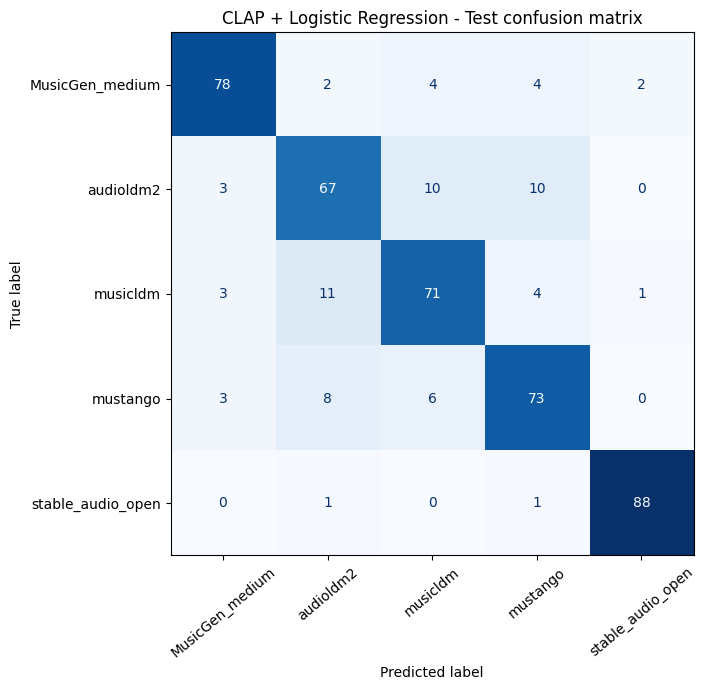

In [6]:
cm = confusion_matrix(y_test, y_test_pred, labels=class_names)
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names).plot(
    ax=ax, cmap='Blues', colorbar=False, xticks_rotation=40, values_format='d'
)
ax.set_title('CLAP + Logistic Regression - Test confusion matrix')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'clap_test_confusion_matrix.png', dpi=180)
plt.show()

На test модель правильно класифікувала 377 із 450 прикладів; 73 передбачення виявилися помилковими. Найменше помилок маємо для `stable_audio_open` - 2/90, тоді як для `audioldm2` - 23/90. Зокрема, 10 справжніх `audioldm2` модель визначила як `musicldm` і ще 10  як `mustango`. У зворотному напрямку 11 прикладів `musicldm` були названі `audioldm2`.

Помилки не виглядають рівномірно розподіленими між усіма генераторами: видно групу класів, які модель плутає частіше.

## 3. Most frequent directed and undirected confusions
`audioldm2` → `musicldm` is not identical to `musicldm` → `audioldm2`. Inspect both directions.

Групуємо всі неправильні передбачення за парами генераторів і порахуємо їхню частку серед усіх 73 test-помилок. Розглянемо як напрямлені помилки (`musicldm` → `audioldm2`), так і пари без урахування напряму (`musicldm ↔ audioldm2`). Це допоможе виокремити найбільш проблемні комбінації для подальшого аналізу.

In [7]:
test_rows['is_error'] = test_rows['generator'] != test_rows['predicted_generator']
errors = test_rows.loc[test_rows['is_error']].copy()
error_pairs = (errors.groupby(['generator','predicted_generator'])
               .size().rename('errors').reset_index()
               .sort_values('errors', ascending=False))
error_pairs['percent_of_all_errors'] = (100 * error_pairs['errors'] / max(len(errors), 1)).round(1)
print(f'Total test errors: {len(errors)} / {len(test_rows)}')
display(error_pairs.head(10))
error_pairs.to_csv(RESULTS_DIR / 'clap_test_error_pairs.csv', index=False)

unordered_pairs = errors.apply(
    lambda r: ' ↔ '.join(sorted([r['generator'],r['predicted_generator']])), axis=1
)
display(unordered_pairs.value_counts().head(5).rename_axis('generator_pair').to_frame('errors'))

Total test errors: 73 / 450


,generator,predicted_generator,errors,percent_of_all_errors
8,musicldm,audioldm2,11,15.1
6,audioldm2,mustango,10,13.7
5,audioldm2,musicldm,10,13.7
12,mustango,audioldm2,8,11.0
13,mustango,musicldm,6,8.2
9,musicldm,mustango,4,5.5
1,MusicGen_medium,musicldm,4,5.5
2,MusicGen_medium,mustango,4,5.5
11,mustango,MusicGen_medium,3,4.1
4,audioldm2,MusicGen_medium,3,4.1


,errors
generator_pair,
audioldm2 ↔ musicldm,21
audioldm2 ↔ mustango,18
musicldm ↔ mustango,10
MusicGen_medium ↔ musicldm,7
MusicGen_medium ↔ mustango,7


Найчастіша напрямлена помилка — `musicldm` → `audioldm2` (15.1% усіх помилок). Також помітні `audioldm2` → `musicldm` і `audioldm2` → `mustang` (по 13.7%).

Якщо об'єднати обидва напрями, найбільш проблемною виявляється пара `audioldm2` ↔ `musicldm` (28.8%), а другою `audioldm2` ↔ `mustango` (24.7%). Разом ці дві пари відповідають за 39/73 помилок (53.4%).

Дані результати можуть вказувати на те, що в обраному CLAP feature space їх складніше відокремити лінійним класифікатором, але з одних лише помилок не можна довести, що самі аудіосигнали акустично подібні, для цього потрібна додаткова перевірка.

## 4. Examples with prompts

Матриця й таблиці агрегують помилки, але не показують, що саме містять неправильно класифіковані аудіо. Зіставимо test-передбачення з metadata за обома ключами track_id і generator. Далі візьмемо по одному прикладу з трьох найчастіших напрямлених пар, обравши випадок із найбільшою `predicted_probability` у кожній парі.

Тут `predicted_probability` - вихід класифікатора, такий відбір навмисно показує незвичайні, дуже «впевнені» помилки.

In [ ]:
pilot = pd.read_csv(PROJECT_ROOT / 'data/interim/pilot_metadata.csv', dtype={'track_id': str})
pilot = pilot[['track_id','generator','caption','split']]
errors_with_captions = errors.merge(
    pilot.rename(columns={'split':'metadata_split'}),
    on=['track_id','generator'], how='left', validate='one_to_one'
)

# Choose one example for each of the three most common *directed* confusions.
popular = error_pairs.head(3)[['generator','predicted_generator']]
examples = (errors_with_captions.merge(
    popular, on=['generator','predicted_generator'], how='inner'
).sort_values('predicted_probability', ascending=False)
 .drop_duplicates(['generator','predicted_generator']))
display(examples[[
    'track_id','generator','predicted_generator','predicted_probability','caption'
]])
errors_with_captions.to_csv(RESULTS_DIR / 'clap_test_misclassified_examples.csv', index=False)

,track_id,generator,predicted_generator,predicted_probability,caption
2,bcybO-SMY5E,audioldm2,mustango,0.999991,This rap song features a male voice rapping th...
30,Zxyfhub6nV4,musicldm,audioldm2,0.998214,This audio holds a church bell ringing loudly ...
6,HAHn_zB47ig,audioldm2,musicldm,0.994189,The low quality recording features a groovy fi...


Серед відібраних прикладів є `audioldm2` → `mustango` для опису реп-композиції з чоловічим вокалом (bcybO-SMY5E, `predicted_probability` ≈ 0.99999), `musicldm` → `audioldm2` для опису гучного церковного дзвону (Zxyfhub6nV4, ≈ 0.99821) та `audioldm2` → `musicldm` для опису низькоякісного запису з ритмічним грувом (HAHn_zB47ig, ≈ 0.99419).

Помилки трапляються навіть тоді, коли модель надає передбаченому класу дуже високу оцінку. Це привід окремо **дослідити калібрування впевненості**, якщо така задача буде актуальною надалі. Однак наведені три приклади відібрані саме за високою ймовірністю й мають різні описи — на їх основі не можна стверджувати, що певний жанр чи тип звуку спричиняє помилки. Для перевірки можливої закономірності потрібен аналіз більшої кількості prompts.

# Conclusion

На пілотному **test** з 450 прикладів модель CLAP + Logistic Regression досягла Macro `F1 = 0.8378`, але точність ідентифікації помітно відрізняється для різних генераторів. Найкраще розпізнається `stable_audio_open` (F1 = 0.972), найскладніше - `audioldm2` (F1 = 0.749). Понад половину всіх помилок (53.4%) припадає лише на дві пари: `audioldm2` ↔ `musicldm` та `audioldm2` ↔ `mustango`.

Отже, CLAP embeddings містять корисну інформацію для атрибуції відомих генераторів, але їхня роздільна здатність у поєднанні з Logistic Regression неоднакова для всіх класів.